In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# **CAPSTONE 3**
Analisis Program GrabUnlimited

300.000 Pesanan GrabFood, November 2023-Maret 2024.

---

## **Background Story**

Grab menjalankan program berlangganan **GrabUnlimited**: Membayar tiap bulan untuk mendapatkan promo extra. Program ini berhasil menaikkan frekuensi transaksi, tetapi ada asumsi pemanfaatan celah oleh oknum sindikat yang menyebabkan subsidi yang bocor (Anggaran subsidi lebih dari yang diperlukan) yang mana membuat grab kehilangan uang. Grab secara umum juga tetap memberikan promo untuk non-member maka analisa privilege apa yang didapat oleh member dan non-member dibutuhkan untuk tetap menjaga privilege extra yang dimiliki oleh member GrabUnlimited. 

<img src="Grab Logo - Colored - zonalogo.com.svg" width="150">

---

<img src="GrabUnlimited_Final_Logo_RGB_horizontal.png" width="300">

## **1. Import data**

Sebelum melakukan keseluruhan proses, import data yang dibutuhkan terlebih dahulu

In [53]:
users= pd.read_csv('grab_users.csv')
orders= pd.read_csv('grab_food_orders.csv')
merchants= pd.read_csv('grab_merchants.csv')

Selanjutnya, pembuatan copy untuk mencegah apabila terjadi kesalahan di proses-proses yang akan dilakukan agar dataset yang asli tidak rusak

In [54]:
# Membuat Data Backup sebelum memulai cleaning
users_clean = users.copy()
orders_clean = orders.copy()
merchants_clean = merchants.copy()


## **2. Cleaning Data**
Proses cleaning akan dilakukan untuk memeriksa keseluruhan data dan memperbaiki data yang diperkirakan tidak dibutuhkan atau yang masih dalam bentuk yang tidak sesuai dengan kebutuhan

### **A. Data profiling**
selanjutnya proses data profiling dilakukan untuk memeriksa gambaran besar dari dataset yang digunakan:
- .info() dan .head() akan digunakan untuk memeriksa gambaran besarnya

In [55]:
# .info() memeriksa data type, null, column-nya
orders_clean.info()
users_clean.info()
merchants_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   order_id             300000 non-null  object
 1   merchant_id          300000 non-null  object
 2   user_id              300000 non-null  object
 3   order_status         300000 non-null  object
 4   promo_discount       300000 non-null  int64 
 5   cancel_reason        35780 non-null   object
 6   order_time           300000 non-null  object
 7   driver_arrived_time  270320 non-null  object
 8   completed_time       240093 non-null  object
dtypes: int64(1), object(8)
memory usage: 20.6+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            40000 non-null  object
 1   is_grab_unlimited  40000 non-null  

In [56]:
#.head() digunakan untuk memeriksa 5 data teratas dari masing masing data
print(orders_clean.head())
print(users_clean.head())
print(merchants_clean.head())

          order_id merchant_id    user_id order_status  promo_discount  \
0  GF-ORD-00000001    GF-06555  GB-019659    Completed               0   
1  GF-ORD-00000002    GF-07698  GB-019520       Cancel               0   
2  GF-ORD-00000003    GF-02054  GB-030006     CANCELED           15000   
3  GF-ORD-00000004    GF-05867  GB-021929    Completed           30000   
4  GF-ORD-00000005    GF-06915  GB-008802         DONE               0   

           cancel_reason        order_time driver_arrived_time  \
0                    NaN   12/21/2023 9:43    12/21/2023 10:00   
1  Resto Tidak Ditemukan  12/20/2023 14:01    12/20/2023 14:13   
2             Menu Habis   2/18/2024 12:56     2/18/2024 13:06   
3                    NaN  12/21/2023 16:12    12/21/2023 16:24   
4                    NaN     2/3/2024 9:13       2/3/2024 9:20   

     completed_time  
0  12/21/2023 10:16  
1               NaN  
2               NaN  
3  12/21/2023 16:58  
4     2/3/2024 9:36  
     user_id  is_grab_unli

Pemeriksaan berapa persen member dari GrabUnlimited:

In [57]:
print(users_clean['is_grab_unlimited'].unique())
print(users_clean['is_grab_unlimited'].value_counts())

total_user = len(users_clean)
n_member   = users_clean['is_grab_unlimited'].sum()   # True dihitung sebagai 1
print(f"Non-Member: {(total_user - n_member)/total_user:.2%},Member: {n_member/total_user:.2%}")

[False  True]
is_grab_unlimited
False    24231
True     15769
Name: count, dtype: int64
Non-Member: 60.58%,Member: 39.42%


### **B. Standardization**
setelah dilakukan pengecekan dengan .info() dapat dilihat bahwa Dtype dari dataset masih banyak yang tidak sesuai, maka dari itu akan dilakukan perubahan Dtypes sesuai dengan kebutuhan.
- pd.to_datetime() untuk mengubah Dtype ke datetime, coerce sendiri digunakan untuk mengubah data yang tidak bisa diubah ke datetime menjadi NaT (mempermudah pada saat proses pencarian missing values)

In [58]:
orders_clean['order_time'] =pd.to_datetime(orders_clean['order_time'], errors='coerce')
orders_clean['driver_arrived_time']=pd.to_datetime(orders_clean['driver_arrived_time'], errors='coerce')
orders_clean['completed_time']=pd.to_datetime(orders_clean['completed_time'], errors='coerce')

In [59]:
# cek info lagi
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             300000 non-null  object        
 1   merchant_id          300000 non-null  object        
 2   user_id              300000 non-null  object        
 3   order_status         300000 non-null  object        
 4   promo_discount       300000 non-null  int64         
 5   cancel_reason        35780 non-null   object        
 6   order_time           300000 non-null  datetime64[ns]
 7   driver_arrived_time  270320 non-null  datetime64[ns]
 8   completed_time       240093 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(1), object(5)
memory usage: 20.6+ MB


### **C. Duplicate checking**
dilakukan untuk memeriksa apakah data yang duplikat agar bisa diperbaiki jika ada.

In [60]:
orders_clean.duplicated().sum()
merchants_clean.duplicated().sum()
users_clean.duplicated().sum()

# Print agar ke print satu-satu bukan hanya yg paling bawah
print(orders_clean.duplicated().sum())
print(merchants_clean.duplicated().sum())
print(users_clean.duplicated().sum())

0
0
0


### **D. Fixing inconsistency errors**
Pada dataset ini ditemukan bahwa terdapat inconsistency pada kolom 'order_status' yang mana akan berdampak pada hasil akhir data jika tidak diperbaiki

In [61]:
# cek isi dari 'order_status'
orders_clean["order_status"].unique()

array(['Completed', 'Cancel', 'CANCELED', 'DONE', 'Selesai', 'batal',
       'Failed'], dtype=object)

In [62]:
status_map = {
    'Completed': 'Completed', 'Selesai': 'Completed', 'DONE': 'Completed',
    'Failed':'Cancelled', 'CANCELED': 'Cancelled', 'batal': 'Cancelled',
    'Cancel': 'Cancelled'
}
orders_clean['order_status'] = orders_clean['order_status'].map(status_map)
print(orders_clean['order_status'].value_counts())

order_status
Completed    240093
Cancelled     59907
Name: count, dtype: int64


### **E. Missing values**
pada proses ini dilakukan pemeriksaan pada dataset untuk mencari nilai Null, agar bisa diberi perlakuan sesuai dengan kebutuhan.

In [63]:
# Cek Missing Values di data

print(f'Missing Values in orders_clean:{orders_clean.isna().sum()}')
print(f'Missing Values in merchants_clean:{merchants_clean.isna().sum()}')
print(f'Missing Values in users_clean:{users_clean.isna().sum()}')

Missing Values in orders_clean:order_id                    0
merchant_id                 0
user_id                     0
order_status                0
promo_discount              0
cancel_reason          264220
order_time                  0
driver_arrived_time     29680
completed_time          59907
dtype: int64
Missing Values in merchants_clean:merchant_id      0
merchant_name    0
cuisine_type     0
city             0
dtype: int64
Missing Values in users_clean:user_id              0
is_grab_unlimited    0
account_age_days     0
dtype: int64


Ditemukan bahwa ada 3 kolom yang memiliki Null, dikarenakan kolom 'driver_arrived_time' dan 'completed_time' Dtype nya datetime maka akan kita ubah menjadi NaT (Not a Time) untuk menandai data tanggal atau waktu yang kosong/tidak valid, serta memeriksa rasio persentase nya.

In [64]:
# Membuat Variabel untuk mengitung jumlah data completed_time yang masih rusak/aneh
bad_time = orders_clean['completed_time'] < orders_clean['driver_arrived_time']

# Mengubah data completed_time yang rusak/aneh menjadi NaT
orders_clean.loc[bad_time, 'completed_time'] = pd.NaT

# memeriksa jumlah data completed_time yang masih rusak/aneh setelah diubah menjadi NaT
print(f"Jumlah data completed_time yang masih rusak/aneh: {orders_clean['completed_time'].isna().sum()}")

print (f"Jumlah bad_time tersisa: {(orders_clean['completed_time'] < orders_clean['driver_arrived_time']).sum()}")

# Cek Rasio Persentase Jumlah NaT dan jumlah data valid dari completed_time
total = len(orders_clean)
n_nat = orders_clean['completed_time'].isna().sum()
print(f"NaT: {n_nat/total:.2%}, Valid: {(total-n_nat)/total:.2%}")

Jumlah data completed_time yang masih rusak/aneh: 69510
Jumlah bad_time tersisa: 0
NaT: 23.17%, Valid: 76.83%


tersisa 1 kolom yang masih Null yaitu 'cancel_reason' tapi di kolom ini Null dapat menggambarkan 2 hal yang berbeda yaitu order telah selesai maka tidak ada pembatalan dan pembatalan dilakukan tanpa alasan.

Sebelum .fillna() dilakukan, loc akan digunakan terlebih dahulu dan memfilter sesuai dengan kondisi sebelum .fillna() mengisinya dengan alasan yang sesuai

In [65]:
# .loc dilakukan untuk menyesuaikan dengan order statusnya dahulu, sebelum mengisi nilai null dengan keadaan masing masing order status
orders_clean.loc[(orders_clean['order_status'] == 'Completed') 
                 & (orders_clean['cancel_reason'].isna()), 'cancel_reason'] = 'Order Completed'

orders_clean.loc[(orders_clean['order_status'] == 'Cancelled') 
                 & (orders_clean['cancel_reason'].isna()), 'cancel_reason'] = 'Without Reason'

# Cek Hasilnya
orders_clean.groupby('order_status')['cancel_reason'].value_counts(dropna=False)

order_status  cancel_reason        
Cancelled     Without Reason            24127
              Resto Tutup               11920
              Resto Tidak Ditemukan     11808
              Driver Terlalu Jauh        6036
              Menu Habis                 6016
Completed     Order Completed          240093
Name: count, dtype: int64

Setelah dilakukan crosschecking antara order_status dan cancel_reason ditemukan bahwa dari **264220** data Null **24127** nya merupakan cancelled order dengan pembatalan tidak beralasan dan **240093** nya merupakan order yang sudah terselesaikan.

### **F. Outlier checking**
proses ini dilakukan untuk memeriksa data yang aneh dan mustahil terjadi di dataset, kolom 'promo_discount' sendiri terindikasi memiliki outlier maka akan diperiksa.

Promo Discount

In [66]:
print(orders_clean['promo_discount'].describe())
print((orders_clean['promo_discount'] < 0).sum())


count    3.000000e+05
mean     6.035158e+04
std      7.018429e+05
min     -5.000000e+03
25%      0.000000e+00
50%      1.000000e+04
75%      2.000000e+04
max      9.999999e+06
Name: promo_discount, dtype: float64
1403


ditemukan bahwa pada promo_discount terdapat nilai minimal dibawah 0 yang mana tidak masuk akal atau mustahil terjadi untuk promo dan juga nilai maksimal berada di angka 9.999.999 yang juga mustahil terjadi untuk promo makanan.

selanjutnya setelah outlier-nya sudah terdeteksi maka data akan di perbaiki

In [67]:
# Cleaning data promo_discount, dimana promo yang tidak masuk akal (9999999) dan promo yang nilainya dibawah 0 atau negatif
# akan diubah menjadi NaN
orders_clean.loc[orders_clean['promo_discount'] == 9999999, 'promo_discount'] = np.nan
orders_clean.loc[orders_clean['promo_discount'] < 0, 'promo_discount'] = np.nan


In [68]:
# Cek kembali data yang tadi rusak/aneh, apakah sudah diubah menjadi NaN atau belum
print(orders_clean['promo_discount'].describe())

count    297109.000000
mean      10879.811786
std       10389.754556
min           0.000000
25%           0.000000
50%       10000.000000
75%       20000.000000
max       30000.000000
Name: promo_discount, dtype: float64


Cek Rasio jumlah NaN dan juga jumlah NaT

In [69]:
# Cek Rasio persentase jumlah NaN dan jumlah data valid dari promo_discount
total = len(orders_clean)
n_missing = orders_clean['promo_discount'].isna().sum()
n_valid = total - n_missing
print(f"NaN: {n_missing/total:.2%}, Valid: {n_valid/total:.2%}")


NaN: 0.96%, Valid: 99.04%


setelah pengecekan rasio, ditemukan bahwa **nilai promo yang tidak valid atau mustahil** berjumlah **0,96%** yang mana akan di drop karena hanya akan merusak data jika di tetap dipertahankan

In [70]:
orders_clean = orders_clean.dropna(subset=['promo_discount'])

In [71]:
# Cek Rasio Persentase setelah NaN di drop
total = len(orders_clean)
n_missing = orders_clean['promo_discount'].isna().sum()
n_valid = total - n_missing
print(f"NaN: {n_missing/total:.2%}, Valid: {n_valid/total:.2%}")

NaN: 0.00%, Valid: 100.00%


setelah promo tidak valid di drop semua , maka hanya ada promo valid yang tersisa.

### **G. Merging cleaned data**
merge dilakukan agar mempermudah pemeriksaan silang antar dataset (orders,users,merchants)

In [72]:
grab_clean = orders_clean.merge(merchants_clean, on='merchant_id', how='left')
grab_clean = grab_clean.merge(users_clean, on='user_id', how='left')


Memeriksa atau Memvalidasi data sebelum dan sesudah di merge

In [73]:
# harus sama panjang dari datasetnya
print(len(orders_clean), len(grab_clean))          
print(grab_clean.isna().sum()  )                   
print(f"Duplicated: {grab_clean.duplicated(subset='order_id').sum()}")    


297109 297109
order_id                   0
merchant_id                0
user_id                    0
order_status               0
promo_discount             0
cancel_reason              0
order_time                 0
driver_arrived_time    29367
completed_time         68892
merchant_name              0
cuisine_type               0
city                       0
is_grab_unlimited          0
account_age_days           0
dtype: int64
Duplicated: 0


### **DESCRIPTIVE INSIGHT**

Proses cleaning atas 300.000 pesanan menghasilkan lima temuan berikut.

---

**1. Kerusakan ada di level nilai, bukan di level relasi**

Ketiga tabel bersih dari duplikat (0 baris), dan setelah di-merge tidak ada satu pun NaN dari kolom merchant maupun user - seluruh `merchant_id` dan `user_id` di tabel pesanan punya pasangan di tabel master. Dari 300.000 baris, **297.109 (99,04%) dipertahankan**. Artinya masalah dataset ini bukan pencatatan ganda atau relasi yang putus, melainkan konsistensi penulisan dan kewajaran nilai.

---

**2. Tujuh label untuk dua kondisi**

`order_status` memakai 7 label (`Completed`, `Selesai`, `DONE`, `Cancel`, `CANCELED`, `batal`, `Failed`) untuk 2 kondisi sebenarnya. Tanpa normalisasi, laporan hanya membaca 179.697 pesanan sukses, padahal aslinya 240.093 - **60.396 pesanan (25,2%) hilang dari laporan.** Setelah dibakukan: **80,03% selesai, 19,97% batal.**

---

**3. NaN tidak selalu berarti data hilang**

`cancel_reason` memiliki 264.220 NaN (88,07%) - angka yang terlihat menakutkan. Setelah diperiksa silang dengan `order_status`, ternyata 240.093 di antaranya adalah pesanan selesai yang memang tidak punya alasan batal. **Missing sejati hanya 24.127**, yaitu 40,27% dari pesanan batal.

Pola serupa pada `driver_arrived_time`: 29.680 NaN, dan **seluruhnya ada di pesanan batal, nol di pesanan selesai.** Ini bukan data rusak, melainkan rekaman kejadian nyata - 49,54% pembatalan terjadi sebelum driver tiba di resto. Menilai missing value per kolom tanpa konteks kolom lain akan salah 10 kali lipat.

---

**4. 0,96% data merusak seluruh statistik promo**

`promo_discount` mentah memuat 1.403 nilai negatif (hingga -Rp 5.000) dan 1.488 nilai Rp 9.999.999. Hanya **2.891 baris (0,96%)**, tetapi efeknya:

| | Sebelum | Sesudah |
|---|---|---|
| Mean | Rp 60.351 | Rp 10.879 |
| Std | Rp 701.843 | Rp 10.390 |

Rata-rata subsidi menggelembung **5,5 kali lipat** dan standar deviasi **67,6 kali lipat**. Setelah bersih, promo ternyata hanya punya 5 nilai tetap (Rp 0, 10.000, 15.000, 20.000, 30.000) - **kategorikal, bukan kontinu** - dengan 38,81% pesanan tanpa promo sama sekali.

---

**5. 9000+ pesanan melanggar hukum fisika**

Ditemukan **9.603 pesanan berstatus selesai (4,00%) yang jam selesainya mendahului jam driver tiba di resto** - makanan tercatat sampai ke pelanggan sebelum diambil dari merchant. Tidak ada validasi apa pun di sistem yang mencegah ini tersimpan.

EXTRAS:
- Memecah Datetime menjadi lebih rinci untuk mempermudah pengecekan berbasis waktu
- Membuat variabel untuk memeriksa berapa lama order berjalan (dalam bentuk menit)

In [74]:
grab_clean['order_hour'] = grab_clean['order_time'].dt.hour
grab_clean['order_day'] = grab_clean['order_time'].dt.day_name()

In [75]:
grab_clean['duration_min'] = (grab_clean['completed_time'] - grab_clean['order_time']).dt.total_seconds() / 60
grab_clean['duration_min'].describe()

count    228217.000000
mean         36.504721
std           9.664603
min          15.000000
25%          29.000000
50%          37.000000
75%          44.000000
max          58.000000
Name: duration_min, dtype: float64

## **3. EDA: Exploratory Data Analysis**
Tujuan:
1. Memverifikasi bahwa proses cleaning benar-benar bersih
2. Memahami distribusi tiap kolom secara mandiri (univariate)
3. Mencari hubungan antar kolom (bivariate)
4. Menguji asumsi yang ada di background story

In [76]:
plt.rcParams['figure.figsize'] = (10, 4)
sns.set_style('whitegrid')

In [77]:
grab_clean.head()

,order_id,merchant_id,user_id,order_status,promo_discount,cancel_reason,order_time,driver_arrived_time,completed_time,merchant_name,cuisine_type,city,is_grab_unlimited,account_age_days,order_hour,order_day,duration_min
0,GF-ORD-00000001,GF-06555,GB-019659,Completed,0.0,Order Completed,2023-12-21 09:43:00,2023-12-21 10:00:00,2023-12-21 10:16:00,Resto GrabMantap 6554,Fast Food,Bandung,False,1363,9,Thursday,33.0
1,GF-ORD-00000002,GF-07698,GB-019520,Cancelled,0.0,Resto Tidak Ditemukan,2023-12-20 14:01:00,2023-12-20 14:13:00,NaT,Resto GrabMantap 7697,Ayam Geprek,Medan,True,472,14,Wednesday,NaN
2,GF-ORD-00000003,GF-02054,GB-030006,Cancelled,15000.0,Menu Habis,2024-02-18 12:56:00,2024-02-18 13:06:00,NaT,Resto GrabMantap 2053,Fast Food,Bandung,True,1226,12,Sunday,NaN
3,GF-ORD-00000004,GF-05867,GB-021929,Completed,30000.0,Order Completed,2023-12-21 16:12:00,2023-12-21 16:24:00,2023-12-21 16:58:00,Resto GrabMantap 5866,Martabak,Bogor,True,604,16,Thursday,46.0
4,GF-ORD-00000005,GF-06915,GB-008802,Completed,0.0,Order Completed,2024-02-03 09:13:00,2024-02-03 09:20:00,2024-02-03 09:36:00,Resto GrabMantap 6914,Fast Food,Medan,False,1479,9,Saturday,23.0


### **A. Cleaning verification**
dilakukan untuk memverifikasi apakah data cleaning sudah benar, dan tidak ada yang miss.

In [78]:
print('Promo negatif tersisa    :', (grab_clean['promo_discount'] < 0).sum())
print('Promo > 30.000 tersisa   :', (grab_clean['promo_discount'] > 30000).sum())
print('Logical error tersisa    :', (grab_clean['completed_time'] < grab_clean['driver_arrived_time']).sum())
print('Label order_status       :', grab_clean['order_status'].unique())
print('Duplikat order_id        :', grab_clean.duplicated(subset='order_id').sum())
print('Jumlah baris             :', len(grab_clean))

Promo negatif tersisa    : 0
Promo > 30.000 tersisa   : 0
Logical error tersisa    : 0
Label order_status       : ['Completed' 'Cancelled']
Duplikat order_id        : 0
Jumlah baris             : 297109


### **B. Feature Engineering**
proses ini berfungsi untuk merincikan variabel yang akan digunakan pada proses selanjutnya.



In [79]:
grab_clean['order_hour']  = grab_clean['order_time'].dt.hour
grab_clean['order_day']   = grab_clean['order_time'].dt.day_name()
grab_clean['order_month'] = grab_clean['order_time'].dt.to_period('M')
grab_clean['duration_min'] = (grab_clean['completed_time'] - grab_clean['order_time']).dt.total_seconds() / 60

grab_clean[['order_hour', 'order_day', 'order_month', 'duration_min']].head()

,order_hour,order_day,order_month,duration_min
0,9,Thursday,2023-12,33.0
1,14,Wednesday,2023-12,NaN
2,12,Sunday,2024-02,NaN
3,16,Thursday,2023-12,46.0
4,9,Saturday,2024-02,23.0


### **C. Distribusi tiap kolom**

#### **1. Order status**
 .mul() digunakan untuk perkalian disini 100 karena ingin membuat menjadi persentase dan round digunakan untuk membulatkan desimalnya

In [80]:
grab_clean['order_status'].value_counts()
grab_clean['order_status'].value_counts(normalize=True).mul(100).round(2)

order_status
Completed    80.04
Cancelled    19.96
Name: proportion, dtype: float64

#### **2. promo discount**

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25524\1159437837.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='promo_discount', data=grab_clean, palette='crest')


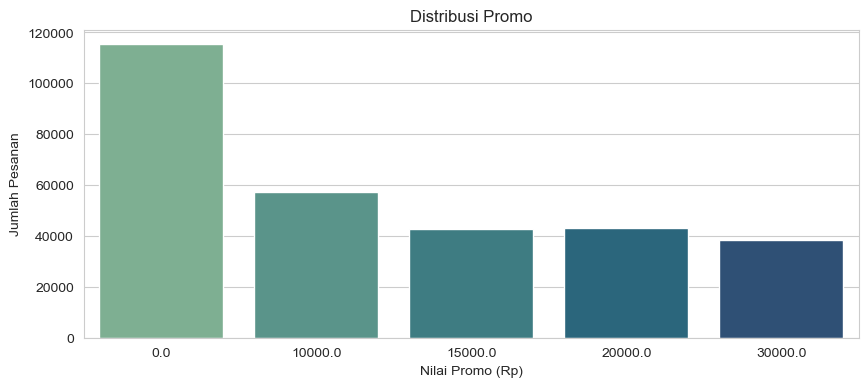

In [81]:
sns.countplot(x='promo_discount', data=grab_clean, palette='crest')
plt.title('Distribusi Promo')
plt.xlabel('Nilai Promo (Rp)'); plt.ylabel('Jumlah Pesanan')
plt.show()

In [82]:
grab_clean['promo_discount'].value_counts()

promo_discount
0.0        115312
10000.0     57388
20000.0     43028
15000.0     42892
30000.0     38489
Name: count, dtype: int64

Berdasarkan data diatas:
- Promo yang paling banyak didapatkan customer adalah **0** dengan jumlah transaksi sebanyak **115.312** sedangkan yang terendah didapatkan oleh **30.000** dengan jumlah transaksi sebanyak **38.489**

#### **3. cuisine types & cities**


C:\Users\ASUS\AppData\Local\Temp\ipykernel_25524\2532196272.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='cuisine_type', data=grab_clean, palette= 'crest',


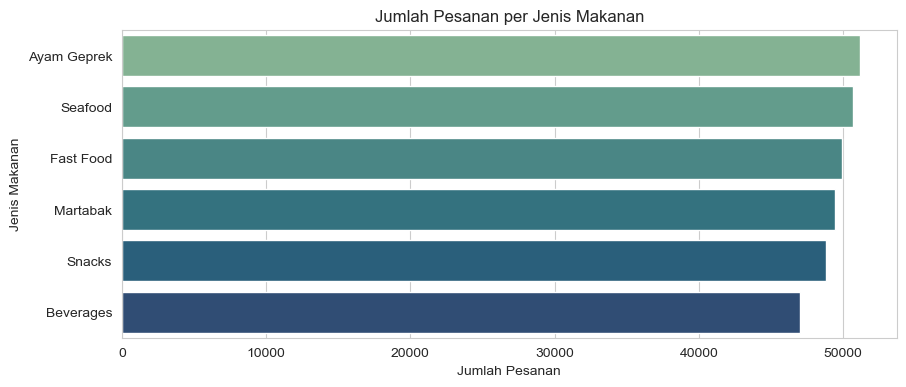

In [83]:
sns.countplot(y='cuisine_type', data=grab_clean, palette= 'crest',
              order=grab_clean['cuisine_type'].value_counts().index)
plt.title('Jumlah Pesanan per Jenis Makanan')
plt.xlabel('Jumlah Pesanan'); plt.ylabel('Jenis Makanan')
plt.show()

In [84]:
print(grab_clean['cuisine_type'].value_counts(normalize=True).mul(100).round(2))
print(grab_clean['city'].value_counts())

cuisine_type
Ayam Geprek    17.22
Seafood        17.06
Fast Food      16.81
Martabak       16.63
Snacks         16.44
Beverages      15.84
Name: proportion, dtype: float64
city
Bekasi       32222
Surabaya     30374
Bogor        30144
Bandung      30141
Medan        29950
Tangerang    29598
Makassar     29218
Depok        29160
Bali         28647
Jakarta      27655
Name: count, dtype: int64


Berdasarkan data diatas didapatkan hasil sebagai berikut:

*   **Tipe Makanan Paling Populer (`cuisine_type`):** Proporsi pemesanan makanan terdistribusi cukup merata di kisaran 15% - 17%. **Ayam Geprek (17.22%)** memimpin sebagai menu yang paling banyak dipesan, bersaing ketat dengan **Seafood (17.06%)** dan **Fast Food (16.81%)**.
*   **Sebaran Kota Pemesan (`city`):** Volume pesanan tersebar luas di berbagai kota besar dengan rentang 27 ribu hingga 32 ribu pesanan per kota. **Bekasi** menempati posisi pertama sebagai penyumbang pesanan terbanyak (32.222 pesanan), sedangkan **Jakarta** berada di urutan terbawah dari top 10 kota ini.

**Pasar makanan dan juga order tiap kota terdistribusi secara merata**

#### **4. Umur akun**

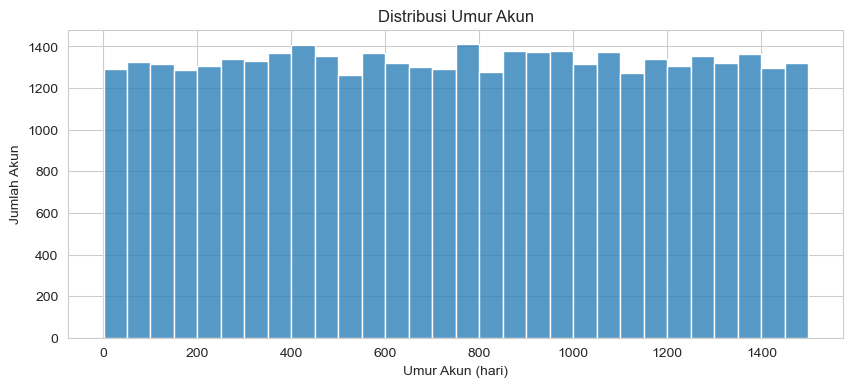

In [85]:
sns.histplot(grab_clean.drop_duplicates('user_id')['account_age_days'], bins=30)
plt.title('Distribusi Umur Akun')
plt.xlabel('Umur Akun (hari)'); plt.ylabel('Jumlah Akun')
plt.show()

Berdasarkan data diatas dapat disimpulkan bahwa persebaran umur akun cukup merata, tidak ada perbedaan yang sangat signifikan.

#### **5. Durasi pengantaran**


count    228217.000000
mean         36.504721
std           9.664603
min          15.000000
25%          29.000000
50%          37.000000
75%          44.000000
max          58.000000
Name: duration_min, dtype: float64
Baris tanpa durasi: 68892


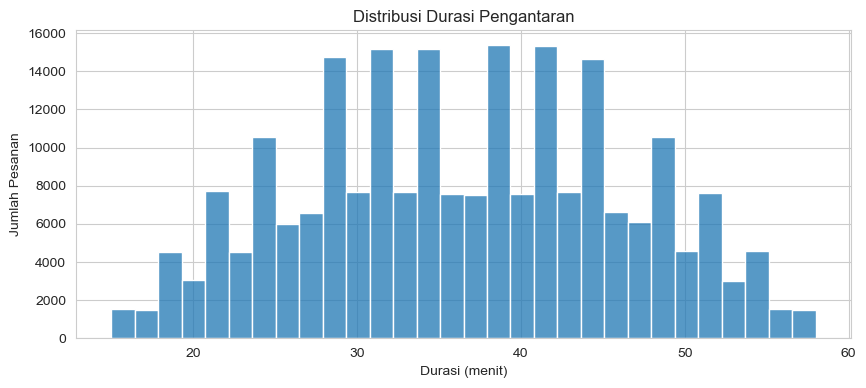

In [86]:
print(grab_clean['duration_min'].describe())
print('Baris tanpa durasi:', grab_clean['duration_min'].isna().sum())

sns.histplot(grab_clean['duration_min'], bins=30)
plt.title('Distribusi Durasi Pengantaran')
plt.xlabel('Durasi (menit)'); plt.ylabel('Jumlah Pesanan')
plt.show()

66.619 baris tidak punya durasi (order batal + logical error).

dari data diatas dapat disimpulkan bahwa rata-rata waktu pengantaran selama 36.5 menit dan hanya berlaku untuk 77.6% data, karena sisanya merupakan order batal dan juga logical error.

### **D. Analisis waktu**
- Pola per jam
- persebaran order dalam satuan hari
- tren bulanan yang terjadi

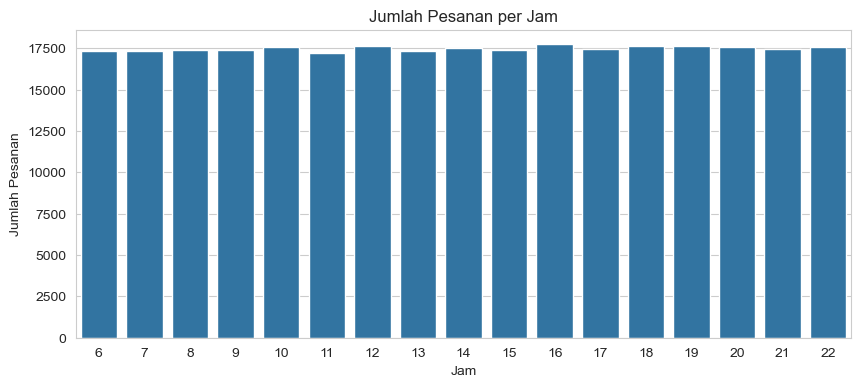

In [87]:
sns.countplot(x='order_hour', data=grab_clean)
plt.title('Jumlah Pesanan per Jam')
plt.xlabel('Jam'); plt.ylabel('Jumlah Pesanan')
plt.show()

Order hanya ada di jam 06:00–22:00, dan rata di angka 17.219–17.736 per jam. Tidak ada lonjakan makan siang maupun makan malam 

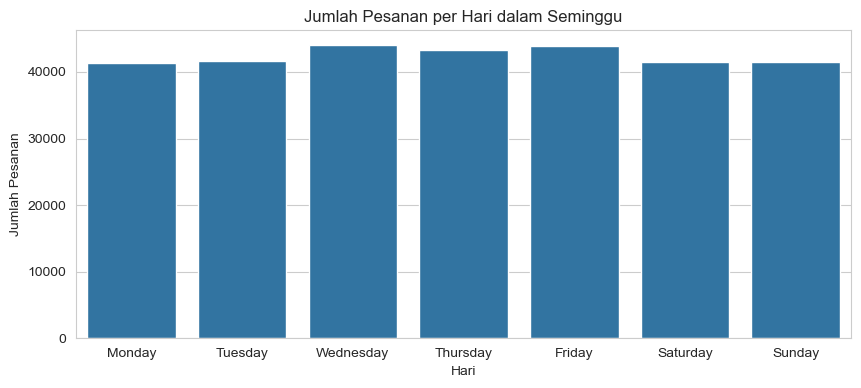

In [88]:
urutan_hari = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sns.countplot(x='order_day', data=grab_clean, order=urutan_hari)
plt.title('Jumlah Pesanan per Hari dalam Seminggu')
plt.xlabel('Hari'); plt.ylabel('Jumlah Pesanan')
plt.show()

melalui data diatas dapat dilihat bahwa data tersebar secara merata tidak ada lonjakan di hari tertentu dengan hari Rabu **44.048** tertinggi sedangkan Senin **41.278** terendah dengan selisih **6,7%**.

### **E. Bivariate**

In [89]:
# membuat helper dengan lambda yang mana berfungsi untuk menghitung persentase pembatalan pesanan (cancel rate) berdasarkan kategori
def cancel_rate(kolom):
    return (grab_clean.groupby(kolom)['order_status']
                      .apply(lambda x: (x == 'Cancelled').mean() * 100)
                      .round(2).sort_values(ascending=False))

print(cancel_rate('city'))
print(cancel_rate('cuisine_type'))
print(cancel_rate('order_hour'))
print(cancel_rate('order_month'))

city
Jakarta      20.31
Depok        20.12
Surabaya     20.11
Makassar     20.06
Bandung      20.02
Bekasi       19.98
Bali         19.92
Medan        19.74
Tangerang    19.70
Bogor        19.64
Name: order_status, dtype: float64
cuisine_type
Martabak       20.15
Snacks         20.01
Seafood        20.00
Ayam Geprek    19.89
Fast Food      19.84
Beverages      19.83
Name: order_status, dtype: float64
order_hour
6     20.42
22    20.41
11    20.35
14    20.17
17    20.16
8     20.14
19    20.12
20    20.06
15    20.02
12    19.93
7     19.89
18    19.88
21    19.85
13    19.63
9     19.50
16    19.47
10    19.28
Name: order_status, dtype: float64
order_month
2024-01    20.11
2024-02    20.10
2023-12    19.86
2023-11    19.85
2024-03    19.85
Freq: M, Name: order_status, dtype: float64


berdasarkan persentase pembatalan yang sudah dilakukan, didapatkan bahwa pada seluruh kategori persentase pembatalannya ada di sekitar 20%.

- kota: 19,64–20,31%
- makanan: 19,83–20,15%
- jam: 19,28–20,42%, 
- bulan: 19,85–20,11%.

Selanjutnya, akan dilakukan pemeriksaan durasi pengantaran tiap kota

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25524\1189426848.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='city', y='duration_min', data=grab_clean, palette='crest')


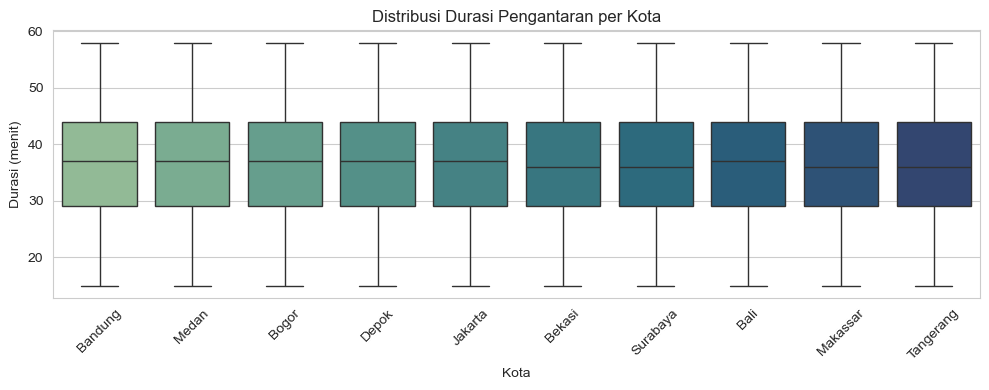

            mean  median   std
city                          
Bali       36.51    37.0  9.66
Bandung    36.53    37.0  9.69
Bekasi     36.52    36.0  9.64
Bogor      36.52    37.0  9.72
Depok      36.48    37.0  9.67
Jakarta    36.50    37.0  9.63
Makassar   36.53    36.0  9.65
Medan      36.61    37.0  9.62
Surabaya   36.45    36.0  9.69
Tangerang  36.40    36.0  9.68


In [90]:
sns.boxplot(x='city', y='duration_min', data=grab_clean, palette='crest')
plt.title('Distribusi Durasi Pengantaran per Kota')
plt.xlabel('Kota'); plt.ylabel('Durasi (menit)')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

print(grab_clean.groupby('city')['duration_min'].agg(['mean','median','std']).round(2))

berdasarkan data diatas, didapatkan kesimpulan bahwa waktu pengantaran tidak berbeda signifikan:
- tertinggi di dimiliki oleh Bali dengan waktu rata-rata 36.51 menit
- terendah dimiliki oleh Tangerang dengan waktu rata-rata 36.40 menit

lalu pemeriksaan alasan pembatalan

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25524\613922361.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='cancel_reason', palette='crest', data=batal, order=batal['cancel_reason'].value_counts().index)


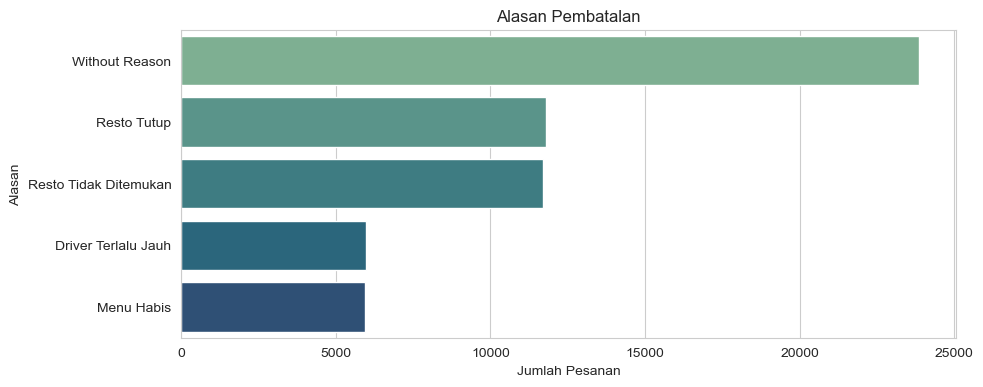

cancel_reason
Without Reason           40.26
Resto Tutup              19.89
Resto Tidak Ditemukan    19.72
Driver Terlalu Jauh      10.07
Menu Habis               10.05
Name: proportion, dtype: float64


In [91]:
batal = grab_clean[grab_clean['order_status'] == 'Cancelled']
sns.countplot(y='cancel_reason', palette='crest', data=batal, order=batal['cancel_reason'].value_counts().index)
plt.title('Alasan Pembatalan')
plt.xlabel('Jumlah Pesanan'); plt.ylabel('Alasan')
plt.show()

print(batal['cancel_reason'].value_counts(normalize=True).mul(100).round(2))

dari data pembatalan diatas didapatkan hasil sebagai berikut:
- Pembatalan tanpa alasan memiliki persentase tertinggi sebesar 40.26%
- Pembatalan dengan alasan menu habis memiliki persentase terendah sebesar 10.05%

### **F. Member dan non-member**
---

**Rasio populasi**

In [92]:
users_clean['is_grab_unlimited'].value_counts(normalize=True).mul(100).round(2)


is_grab_unlimited
False    60.58
True     39.42
Name: proportion, dtype: float64

Rasio yang didapatkan adalah
- Member: 39.42%
- Non-member: 60.58%

---

**apakah promo member > non-member?**

In [93]:
pd.crosstab(grab_clean['is_grab_unlimited'],
                  grab_clean['promo_discount'] > 0, normalize='index').mul(100).round(2)

promo_discount,False,True
is_grab_unlimited,,
False,38.85,61.15
True,38.76,61.24


dari data diatas didapatkan bahwa promo yang didapatkan oleh member tidak berbeda signifikan dengan non-member, dengan persentase promo yang didapat:
- Member: 61.24%
- Non-member: 61.15%

---

**Apakah promo yang didapat member lebih besar daripada non-member?**

In [94]:
grab_clean.groupby('is_grab_unlimited')['promo_discount'].agg('mean').round(0)

is_grab_unlimited
False    10883.0
True     10875.0
Name: promo_discount, dtype: float64

berdasarkan pemeriksaan data diatas dapat disimpulkan bahwa rata-rata promo yang didapat oleh member lebih kecil dibandingkan non-member, dengan rata-rata:
- Member: 10.875
- Non-member: 10.883

**apakah member lebih sering order?**

In [95]:
# Menghitung member dan non member dengan user id nya, 
# .agg() dipakai untuk menhitung dengan banyak perhitungan sekaligus dalam hal ini (count dan nunique)
#  yang digunakan untuk menghitung jumlah total order dan juga jumlah total user unik 
# .assign() digunakan untuk membuat kolom baru, yang mana di dalamnya terdapat syntax lambda d
# yang berfungsi untuk membagi total order/total user unik
grab_clean.groupby('is_grab_unlimited')['user_id'].agg(['count','nunique']).assign(order_per_user=lambda d: d['count'] / d['nunique']).round(2)

,count,nunique,order_per_user
is_grab_unlimited,,,
False,180220,24217,7.44
True,116889,15758,7.42


berdasarkan data yang didapat, member dan non-member rata-rata pesanan yang dilakukan hanya selisih 0.2 dengan non-member yang lebih banyak.

**apakah dengan membership order lebih cepat selesai?**

In [96]:
grab_clean.groupby('is_grab_unlimited')['duration_min'].mean().round(2)

is_grab_unlimited
False    36.52
True     36.48
Name: duration_min, dtype: float64

berdasarkan data yang dihasilkan, member mendapatkan rata-rata pesanan selesai lebih cepat di **36.48 menit** sedangkan non-member di **36.52 menit**

### **G. Ghost Account**
proses pemeriksaan umur akun menemukan anomali dengan adanya penemuan akun yang memiliki span order date lebih tinggi daripada umur akun itu sendiri.

In [97]:
# menentukan acuan waktunya (last order di dataset)
snapshot = grab_clean['order_time'].max()   # 2024-03-29 22:58

# pengelompokkan data per user id, lalu dilihat min,max, dan count order time nya
user_span = grab_clean.groupby('user_id')['order_time'].agg(['min', 'max', 'count']).reset_index()

# menghitung selisih hari dari order terakhir dan order pertamanya
user_span['span_days'] = (user_span['max'] - user_span['min']).dt.days

# penggabungan variabel baru
user_span = user_span.merge(users_clean, on='user_id', how='left') 

# age_needed berfungsi untuk menghitung selisih order pertama user id itu dengan last order dari dataset
user_span['age_needed'] = (snapshot - user_span['min']).dt.days   # umur minimum yang seharusnya

# penentuan ghost account = jika selisih order pertama user id lebih besar daripada umur akun
user_span['ghost_account'] = user_span['age_needed'] > user_span['account_age_days']

# perhitungan selisih dari umur minimal dan juga umur akun
user_span['gap_days'] = user_span['age_needed'] - user_span['account_age_days'] 

ghost_accounts = user_span[user_span['ghost_account']]

print('Jumlah akun hantu:', len(ghost_accounts), 'dari', len(user_span), 'user')
print(f"Persentase: {user_span['ghost_account'].mean():.2%}")
print('Di antaranya member GrabUnlimited:', ghost_accounts['is_grab_unlimited'].sum())

print('\nContoh 5 kasus paling ekstrim:')
print(ghost_accounts.nlargest(5, 'gap_days')[
    ['user_id', 'account_age_days', 'span_days', 'age_needed', 'gap_days', 'count', 'is_grab_unlimited']
].to_string(index=False))

Jumlah akun hantu: 3362 dari 39975 user
Persentase: 8.41%
Di antaranya member GrabUnlimited: 1360

Contoh 5 kasus paling ekstrim:
  user_id  account_age_days  span_days  age_needed  gap_days  count  is_grab_unlimited
GB-026466                 1        147         148       147      8              False
GB-037026                 2        146         149       147      6              False
GB-003998                 2        139         148       146     13              False
GB-009870                 2        137         148       146     10              False
GB-003427                 3        146         148       145      9              False


**Melihat order dari ghost account**

In [98]:
# Membuat filter berdasarkan user id
ghost_mask = grab_clean['user_id'].isin(ghost_accounts['user_id'])

# Menghitung jumlah keseluruhan order dari ghost account
print('total order dari ghost account :', ghost_mask.sum())

# Memfilter beradasarkan table ghost mask lalu mengambil promo_discountnya
# dan menjumlahkan keseluruhannya dengan sum()
print('Total promo yang menempel: Rp {:,.0f}'.format(grab_clean.loc[ghost_mask, 'promo_discount'].sum()))

# memfilter sama seperti sebelumnya tetapi kondisinya dua 
# yaitu: ghost mask dan juga is grab unlimited. berfungsi untuk melihat total transaksi
# ghost account yang merupakan member
print('Promo ke ghost (member)  : Rp {:,.0f}'.format(
    grab_clean.loc[ghost_mask & grab_clean['is_grab_unlimited'], 'promo_discount'].sum()))

total order dari ghost account : 25548
Total promo yang menempel: Rp 276,350,000
Promo ke ghost (member)  : Rp 111,485,000


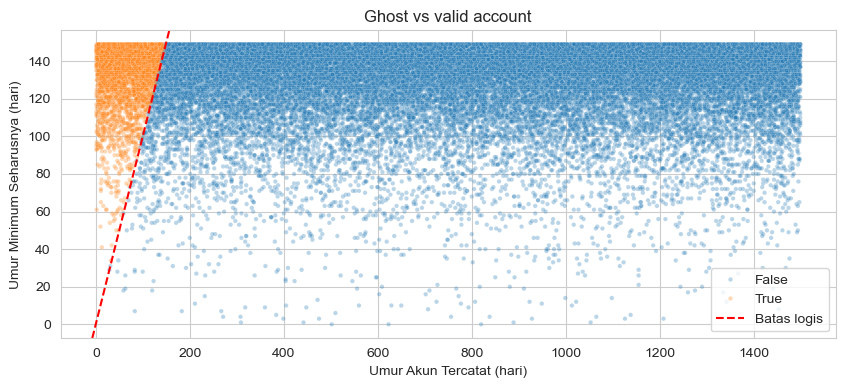

In [99]:
sns.scatterplot(data=user_span, x='account_age_days', y='age_needed',
                hue='ghost_account', alpha=0.3, s=10)
plt.axline((0, 0), slope=1, color='red', linestyle='--', label='Batas logis')
plt.title('Ghost vs valid account')
plt.xlabel('Umur Akun Tercatat (hari)'); plt.ylabel('Umur Minimum Seharusnya (hari)')
plt.legend(); plt.show()

## **4. INSIGHT & RECOMMENDATION**

### **Insight**

#### **1. Program GrabUnlimited tidak memberi privilege apa pun yang terukur**

Member dan non-member dibandingkan pada lima metrik, dan tidak ada satu pun yang berbeda secara berarti:

| Metrik | Member | Non-member |
|---|---|---|
| Pesanan berpromo | 61,24% | 61,15% |
| Rata-rata nilai promo | Rp 10.875 | Rp 10.883 |
| Pesanan per akun | 7,42 | 7,44 |
| Durasi pengantaran | 36,48 mnt | 36,52 mnt |
| Cancel rate | 19,86% | 20,02% |

Pada tiga metrik terakhir, non-member justru sedikit lebih unggul. Dari total anggaran promo **Rp 3.232.490.000**, sebanyak **Rp 1.961.360.000 (60,68%) mengalir ke non-member** - proporsi yang praktis sama dengan porsi populasi mereka (60,58%). Promo dibagikan tanpa memandang status keanggotaan sama sekali.

---

#### **2. Kebocoran subsidi berasal dari cacat sistem, bukan dari sindikat**

Dugaan adanya lingkaran akun tertutup tidak terbukti: rata-rata akun unik per merchant (37,48) hampir sama persis dengan rata-rata jumlah pesanannya (37,50), yang berarti hampir tidak ada pembelian berulang. Yang ditemukan justru dua cacat sistem:

| Sumber | Order | Promo Menempel |
|---|---|---|
| Logical error timestamp | 9.603 | Rp 288.090.000 |
| Order dari akun hantu | 25.548 | Rp 276.350.000 |
| **Gabungan** | **34.320** | **Rp 539.510.000** |

**16,69% anggaran promo menempel pada transaksi yang mustahil terjadi.** Pada subsidi member, porsinya 16,85% - **1 dari setiap 6 rupiah subsidi GrabUnlimited bermasalah.** Angka ini batas bawah, bukan total kerugian.

---

#### **3. Database tidak punya kontrol integritas sama sekali**

Empat bukti dari data mentah: **7 label berbeda untuk 2 kondisi** (menyebabkan 60.396 pesanan sukses atau 25,2% hilang dari laporan), **tiga kolom waktu disimpan sebagai teks** sehingga urutan waktu mustahil tidak bisa ditolak, **2.891 nilai promo di luar nalar lolos masuk** (negatif hingga -Rp 5.000 dan Rp 9.999.999), dan **9.603 pesanan tercatat selesai sebelum driver tiba di resto.**

Nilai promo yang rusak itu hanya 0,96% baris, tetapi cukup untuk menggelembungkan rata-rata subsidi **5,5 kali lipat** (Rp 60.351 menjadi Rp 10.879 setelah dibersihkan).

---

#### **4. Empat dari sepuluh pembatalan tidak bisa diinvestigasi**

Dari 59.289 pesanan batal, **23.872 (40,26%) tidak punya alasan tercatat**, sehingga keputusan kompensasi driver tidak punya dasar. Dari yang beralasan, **66,4% berakar di sisi merchant** - Resto Tutup (11.794) dan Resto Tidak Ditemukan (11.692). Sebanyak **29.367 pembatalan (49,53%) bahkan terjadi sebelum driver sampai di resto.**

---

**Catatan lintas temuan:** seluruh dimensi terdistribusi nyaris seragam - cancel rate antar kota 19,64-20,31%, antar jenis makanan 19,83-20,15%, durasi antar kota hanya berbeda 13 detik, dan volume harian antar bulan hanya berbeda 1,4%. Tidak ada segmen yang bisa dijadikan sasaran perbaikan, sehingga seluruh rekomendasi menyasar sistem, bukan segmen.

### **Recommendation**

#### **1. Kunci integritas data di level sistem**

Terapkan validasi otomatis pada database: tolak pesanan dengan urutan waktu yang mustahil (`completed_time` mendahului `driver_arrived_time`), kunci `order_status` menjadi dua nilai baku, batasi `promo_discount` pada rentang Rp 0-30.000, dan wajibkan `cancel_reason` terisi untuk setiap pembatalan.

**Dampak:** menutup 9.603 pesanan bermasalah senilai **Rp 288.090.000**, mengembalikan 60.396 pesanan sukses yang selama ini hilang dari laporan (25,2%), serta membuat 23.872 pembatalan tanpa alasan bisa diinvestigasi.

---

#### **2. Bekukan subsidi untuk akun yang tidak valid (ghost)**

Terdapat 3.362 akun (8,41%) yang riwayat pesanannya dimulai sebelum akun tersebut dibuat, dan 1.360 di antaranya adalah member GrabUnlimited. Bekukan hak promo akun tersebut dan wajibkan verifikasi ulang identitas untuk mengaktifkannya kembali.

**Dampak:** menghentikan **Rp 276.350.000** subsidi yang mengalir ke 25.548 pesanan dari akun bermasalah.

---

#### **3. Berikan member promo yang memiliki perbedaan signifikan dengan non-member**

Member dan non-member tidak berbeda pada kelima metrik yang diuji - frekuensi promo, nilai promo, jumlah pesanan, kecepatan layanan, dan tingkat pembatalan. Buat tier promo yang benar-benar eksklusif untuk member, lalu ukur ulang setelah satu bulan. Bila frekuensi transaksi member tetap tidak naik, program ini tidak layak dilanjutkan.

**Dampak:** menentukan nasib anggaran **Rp 1.271.130.000**, sekaligus menghentikan **Rp 1.961.360.000 (60,68%)** subsidi yang saat ini mengalir ke non-member tanpa mendorong konversi langganan.

---

#### **4. Perbaiki akurasi data merchant**

Resto Tutup dan Resto Tidak Ditemukan menyumbang 66,4% dari seluruh pembatalan yang beralasan. Keduanya berakar pada data merchant yang tidak akurat, bukan pada kinerja driver. Sinkronkan jam operasional secara otomatis dan verifikasi titik koordinat merchant.

**Dampak:** menyasar 23.486 pembatalan, dan berpotensi menekan 29.367 pembatalan (49,53%) yang terjadi sebelum driver sampai di resto.

---

### **Total Potensi Penghematan**

Rekomendasi 1 dan 2 bersifat teknis dan tidak menyentuh kebijakan bisnis, namun sudah menutup **Rp 539.510.000 (16,69% anggaran promo)** dalam lima bulan, atau **Rp 1.294.824.000 per tahun**.

Rekomendasi 3 dan 4 menentukan arah anggaran Rp 1,27 miliar berikutnya dan memperbaiki 40% pembatalan yang selama ini tidak bisa ditindaklanjuti.

## **SIMULASI PENGHEMATAN**
(bila rekomendasi 1 dan 2 berjalan)

pada proses cleaning, order dengan urutan waktu yang mustahil tidak di drop, hanya diubah completed_time nya menjadi NaT, sehingga baris tersebut masih bisa dipanggil kembali dengan cara order_status 'Completed' tapi completed_time kosong.

logical_error_mask dibuat untuk memanggil baris tersebut agar promo_discount nya bisa dijumlahkan. penggabungan dengan ghost_mask menggunakan `|` bukan penjumlahan, karena ada order yang termasuk keduanya dan akan terhitung dua kali jika dijumlah.

In [100]:
logical_error_mask = (grab_clean['order_status'] == 'Completed') & (grab_clean['completed_time'].isna())

promo_logical_error = grab_clean.loc[logical_error_mask, 'promo_discount'].sum()
promo_ghost         = grab_clean.loc[ghost_mask, 'promo_discount'].sum()
promo_fiktif        = grab_clean.loc[logical_error_mask | ghost_mask, 'promo_discount'].sum()
total_promo         = grab_clean['promo_discount'].sum()

bulan = grab_clean['order_month'].nunique()

print('Total anggaran promo (5 bulan) : Rp {:,.0f}'.format(total_promo))
print('Potensi penghematan            : Rp {:,.0f} ({:.2f}%)'.format(
      promo_fiktif, promo_fiktif / total_promo * 100))
print('Per bulan                      : Rp {:,.0f}'.format(promo_fiktif / bulan))
print('Proyeksi setahun               : Rp {:,.0f}'.format(promo_fiktif / bulan * 12))

Total anggaran promo (5 bulan) : Rp 3,232,490,000
Potensi penghematan            : Rp 539,510,000 (16.69%)
Per bulan                      : Rp 107,902,000
Proyeksi setahun               : Rp 1,294,824,000


## **Exporting file**

In [101]:
# Flag transaksi bermasalah
grab_clean['logical_error'] = (grab_clean['order_status'] == 'Completed') & (grab_clean['completed_time'].isna())
grab_clean['ghost_order']   = grab_clean['user_id'].isin(ghost_accounts['user_id'])
grab_clean['fiktif']        = grab_clean['logical_error'] | grab_clean['ghost_order']

# Kolom bantu untuk sumbu waktu di Tableau
grab_clean['order_date']  = grab_clean['order_time'].dt.date
grab_clean['order_month'] = grab_clean['order_time'].dt.to_period('M').astype(str)

grab_clean.to_csv('grab_tableau.csv', index=False, encoding='utf-8-sig')
print('Baris:', len(grab_clean), '| Kolom:', len(grab_clean.columns))


Baris: 297109 | Kolom: 22
